# Parcial 3 - Clasificación de residuos (Grupo 1)
## PREPARACIÓN DE LOS DATOS


In [31]:
# Libreria para leer el dataset sin descargar las imagenes a mano
import kagglehub

## Importamos librerias

In [32]:
import os
# Configuramos Keras 3 para usar el backend de PyTorch con soporte nativo CUDA en Windows
os.environ["KERAS_BACKEND"] = "torch"

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, precision_recall_fscore_support)

# Verificación de GPU y CUDA
print(f"Backend activo de Keras: {keras.backend.backend()}")
print(f"PyTorch versión: {torch.__version__}")
print(f"CUDA disponible: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    DEVICE = "cuda:0"
    print(f"Usando GPU: {torch.cuda.get_device_name(0)} (CUDA {torch.version.cuda})")
    print(f"Memoria VRAM total: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    DEVICE = "cpu"
    print("ADVERTENCIA: CUDA no está disponible. Se usará CPU.")

Backend activo de Keras: torch
PyTorch versión: 2.14.1+cu130
CUDA disponible: True
Usando GPU: NVIDIA GeForce RTX 5050 Laptop GPU (CUDA 13.0)
Memoria VRAM total: 7.93 GB


## Descargamos el dataset

In [33]:
path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\Carlos\.cache\kagglehub\datasets\asdasdasasdas\garbage-classification\versions\2


## Identificamos el directorio de las imágenes

In [34]:
data_dir = path
for root, dirs, files in os.walk(path):
    if 'cardboard' in dirs and 'glass' in dirs:
        data_dir = root
        break

print("Directorio de imágenes:", data_dir)

Directorio de imágenes: C:\Users\Carlos\.cache\kagglehub\datasets\asdasdasasdas\garbage-classification\versions\2\Garbage classification\Garbage classification


## Carga y redimensionamiento
Las imágenes se redimensionan a 224x224, el tamaño con el que se entrenaron los modelos preentrenados (MobileNetV2, ResNet50, etc.).
Se carga **sin mezclar** (`shuffle=False`) y con etiquetas enteras (`label_mode='int'`), igual que en clase (`sparse_categorical_crossentropy`). La mezcla se hace después, en la partición, para que train, val y test nunca se solapen.

In [35]:
IMG_SIZE = (224, 224)

dataset = keras.utils.image_dataset_from_directory(
    data_dir,
    image_size=IMG_SIZE,
    batch_size=None,      # una imagen por elemento, para pasarlas a arreglos NumPy
    label_mode='int',
    shuffle=False
)

class_names = dataset.class_names
Num_Clases = len(class_names)
print("Clases del dataset:", class_names)

Found 2527 files belonging to 6 classes.
Clases del dataset: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [36]:
# Pasamos todo a arreglos NumPy (uint8 para no gastar memoria)
imagenes, etiquetas = [], []
for img, lbl in dataset:
    imagenes.append(img.numpy().astype('uint8'))
    etiquetas.append(int(lbl.numpy()))

X = np.stack(imagenes)
y = np.array(etiquetas)
del imagenes, etiquetas

print("X:", X.shape, X.dtype)
print("y:", y.shape)

X: (2527, 224, 224, 3) uint8
y: (2527,)


## Visualizar los datos

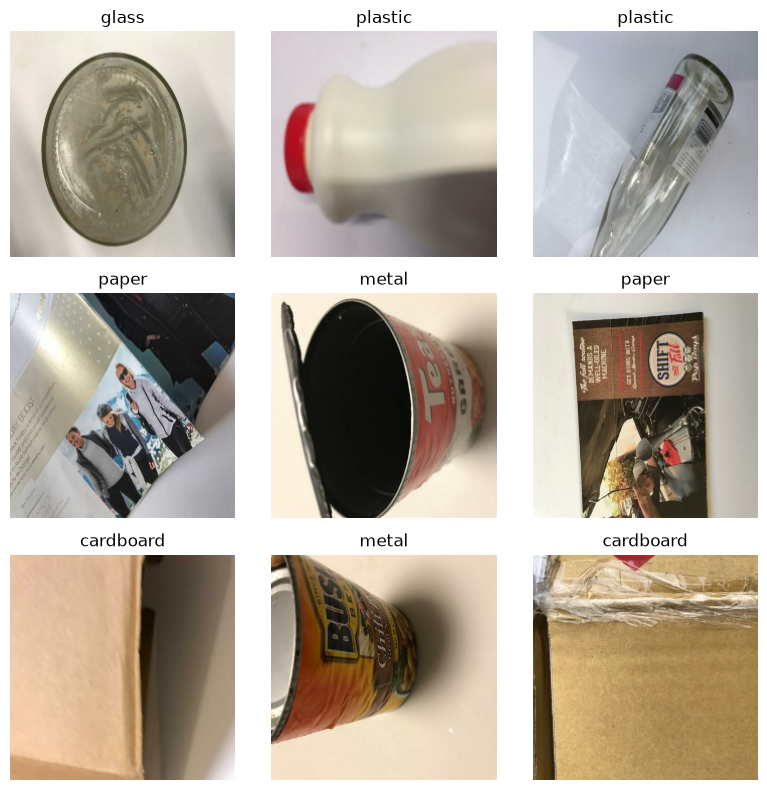

In [37]:
plt.figure(figsize=(8, 8))
rng = np.random.default_rng(42)
for i, idx in enumerate(rng.choice(len(X), 9, replace=False)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X[idx])
    plt.title(class_names[y[idx]])
    plt.axis('off')
plt.tight_layout()
plt.show()

## Distribución de imágenes por clase
Las clases no son uniformes; esto se usa para justificar la partición estratificada y los pesos de clase.

cardboard   403  (15.9%)
glass       501  (19.8%)
metal       410  (16.2%)
paper       594  (23.5%)
plastic     482  (19.1%)
trash       137  (5.4%)


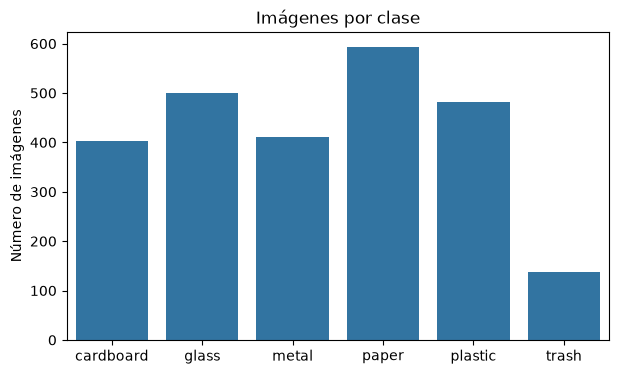

In [38]:
conteo = np.bincount(y, minlength=Num_Clases)
for nombre, n in zip(class_names, conteo):
    print(f"{nombre:10s} {n:4d}  ({n / len(y):.1%})")

plt.figure(figsize=(7, 4))
sns.barplot(x=class_names, y=conteo)
plt.ylabel('Número de imágenes')
plt.title('Imágenes por clase')
plt.show()

## Partición en entrenamiento / validación / prueba (70 / 15 / 15)
Partición **estratificada** (`stratify=y`) con semilla fija: cada conjunto conserva la proporción de clases y las imágenes no se mezclan entre conjuntos.

In [39]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)
del X, X_temp, y_temp

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:   ", X_val.shape, y_val.shape)
print("Prueba:       ", X_test.shape, y_test.shape)

Entrenamiento: (1768, 224, 224, 3) (1768,)
Validación:    (379, 224, 224, 3) (379,)
Prueba:        (380, 224, 224, 3) (380,)


In [40]:
# Verificamos que cada conjunto conserva la proporción de clases
for nombre, yy in [('train', y_train), ('val', y_val), ('test', y_test)]:
    prop = np.bincount(yy, minlength=Num_Clases) / len(yy)
    print(f"{nombre:5s}", np.round(prop, 3))

train [0.16  0.198 0.162 0.235 0.191 0.054]
val   [0.161 0.198 0.161 0.235 0.19  0.055]
test  [0.158 0.2   0.163 0.234 0.192 0.053]


## Normalización de píxeles
Se escalan los valores de [0, 255] a [-1, 1] con `x / 127.5 - 1.0`, que es el rango que espera **MobileNetV2** (el backbone elegido, con pesos de ImageNet). Se normalizan las imágenes, **no** las etiquetas.

> El modelo **no** debe llevar capa de normalización: los datos ya llegan en [-1, 1]. La app web debe aplicar la misma operación: `imagen / 127.5 - 1`.

In [41]:
X_train = X_train.astype('float32') / 127.5 - 1.0
X_val   = X_val.astype('float32') / 127.5 - 1.0
X_test  = X_test.astype('float32') / 127.5 - 1.0

print("Rango train:", X_train.min(), "-", X_train.max())

Rango train: -1.0 - 1.0


Pasos de clase
Compensan el desbalance entre clases. Se pasan a `model.fit(..., class_weight=class_weight)`.

In [42]:
conteo_train = np.bincount(y_train, minlength=Num_Clases)
class_weight = {i: len(y_train) / (Num_Clases * conteo_train[i]) for i in range(Num_Clases)}

for i, w in class_weight.items():
    print(f"{class_names[i]:10s} peso = {w:.2f}")

cardboard  peso = 1.04
glass      peso = 0.84
metal      peso = 1.03
paper      peso = 0.71
plastic    peso = 0.87
trash      peso = 3.07


## Data Augmentation
Se define como capas de Keras. Solo se activan durante el entrenamiento (`training=True`); en validación, prueba y producción no modifican la imagen. Va como **primera parte del modelo**.

In [43]:
# Aceleración por hardware CUDA (F.grid_sample) para las capas de Data Augmentation en Keras 3 + PyTorch
import torch
import torch.nn.functional as F
import keras.src.backend.torch.image as _kimg

def _fast_cuda_affine_transform(images, transform, interpolation='bilinear', fill_mode='constant', fill_value=0, data_format=None):
    data_format = _kimg.backend.standardize_data_format(data_format)
    images = _kimg.convert_to_tensor(images)
    transform = _kimg.convert_to_tensor(transform)
    need_squeeze = False
    if images.ndim == 3:
        images = images.unsqueeze(0)
        need_squeeze = True
    if transform.ndim == 1:
        transform = transform.unsqueeze(0)
    if data_format == 'channels_last':
        images = images.permute(0, 3, 1, 2)
    B, C, H, W = images.shape
    theta = torch.zeros((B, 2, 3), dtype=images.dtype, device=images.device)
    theta[:, 0, 0] = transform[:, 0]
    theta[:, 0, 1] = transform[:, 1]
    theta[:, 0, 2] = (2.0 * transform[:, 2] + (transform[:, 0] + transform[:, 1] - 1.0) * (W - 1)) / max(W - 1, 1)
    theta[:, 1, 0] = transform[:, 3]
    theta[:, 1, 1] = transform[:, 4]
    theta[:, 1, 2] = (2.0 * transform[:, 5] + (transform[:, 3] + transform[:, 4] - 1.0) * (H - 1)) / max(H - 1, 1)
    grid = F.affine_grid(theta, (B, C, H, W), align_corners=True)
    mode = 'bilinear' if interpolation == 'bilinear' else 'nearest'
    pad = 'reflection' if fill_mode in ('reflect', 'mirror') else ('border' if fill_mode == 'nearest' else 'zeros')
    out = F.grid_sample(images, grid, mode=mode, padding_mode=pad, align_corners=True)
    if data_format == 'channels_last':
        out = out.permute(0, 2, 3, 1)
    return out.squeeze(0) if need_squeeze else out

_kimg.affine_transform = _fast_cuda_affine_transform
keras.ops.image.affine_transform = _fast_cuda_affine_transform

data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1, value_range=(-1, 1)),
], name='data_augmentation')

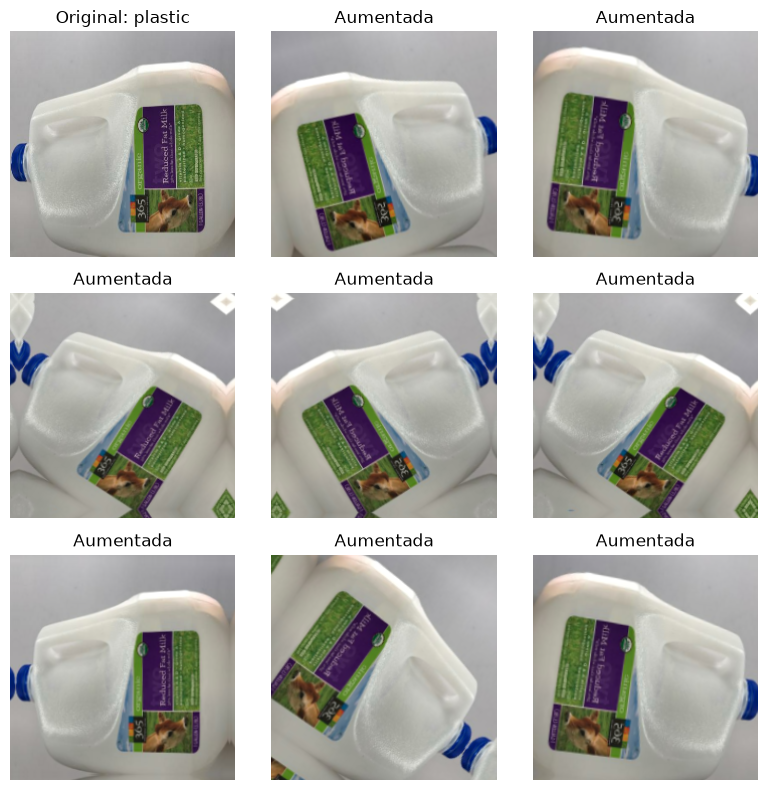

In [44]:
# Una misma imagen con distintas transformaciones aleatorias
imagen = X_train[0:1]
plt.figure(figsize=(8, 8))
plt.subplot(3, 3, 1)
plt.imshow((imagen[0] + 1) / 2)
plt.title('Original: ' + class_names[y_train[0]])
plt.axis('off')
for i in range(8):
    plt.subplot(3, 3, i + 2)
    img_aug = keras.ops.convert_to_numpy(data_augmentation(imagen, training=True)[0])
    plt.imshow(np.clip((img_aug + 1) / 2, 0, 1))
    plt.title('Aumentada')
    plt.axis('off')
plt.tight_layout()
plt.show()

## Resumen de lo que entrega esta sección
Variables listas para el modelo: `X_train, y_train, X_val, y_val, X_test, y_test`, `class_names`, `Num_Clases`, `class_weight`, `IMG_SIZE` y `data_augmentation`.

## Diseño y Arquitectura aplicada

In [45]:
from keras import models, callbacks

# 1. CONFIGURACIÓN GENERAL

Input_Shape = IMG_SIZE + (3,)  # (224, 224, 3)
Epochs = 50
Batch_Size = 32

early_stopping_transfer = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

# ==============================================================================
# 2. MODELO: TRANSFER LEARNING CON MOBILENETV2 (transfer_model)
# - Extracción de características: capas base de MobileNetV2 congeladas
# - Capas ocultas: ReLU (velocidad, no linealidad, evita desvanecimiento de gradiente)
# - Regularización: Batch Normalization y Dropout (evita la memorización / overfitting)
# - Salida: Softmax (distribución de probabilidad en % sobre las 6 clases)
# ==============================================================================
base_model = keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=Input_Shape
)
base_model.trainable = False  # Congelamiento de capas base

transfer_model = models.Sequential([
    layers.Input(shape=Input_Shape),
    data_augmentation,
    base_model,
    layers.BatchNormalization(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(Num_Clases, activation='softmax')
], name='Transfer_Learning_MobileNetV2')

transfer_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

History_Transfer = transfer_model.fit(
    X_train, y_train,
    epochs=Epochs,
    batch_size=Batch_Size,
    validation_data=(X_val, y_val),
    class_weight=class_weight,
    callbacks=[early_stopping_transfer]
)

Model: "Transfer_Learning_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 1280)     │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,435,718 (9.29 MB)

 Trainable params: 175,174 (684.27 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

Epoch 1/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - accuracy: 0.5215 - loss: 1.2929 - val_accuracy: 0.7441 - val_loss: 0.7112
Epoch 2/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - accuracy: 0.7217 - loss: 0.7946 - val_accuracy: 0.7995 - val_loss: 0.5776
Epoch 3/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - accuracy: 0.7755 - loss: 0.6538 - val_accuracy: 0.8417 - val_loss: 0.5150
Epoch 4/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 100ms/step - accuracy: 0.7947 - loss: 0.5602 - val_accuracy: 0.8417 - val_loss: 0.4963
Epoch 5/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - accuracy: 0.8360 - loss: 0.4627 - val_accuracy: 0.8522 - val_loss: 0.4907
Epoch 6/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - accuracy: 0.8371 - loss: 0.4631 - val_accuracy: 0.8338 - val_loss: 0.4687
Epoch 7/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - accuracy: 0.8563 - loss: 0.3861 - val_accuracy: 0.8417 - val_loss: 0.4858
Epoch 8/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - accuracy: 0.8609 - loss: 0.3719 - val_accuracy: 0.



```
# Esto tiene formato de código
```

## EVALUACIÓN DEL MODELO

In [46]:
# ==========================================
# EVALUACIÓN Y COMPARACIÓN DE LOS MODELOS
# ==========================================

import pandas as pd

def evaluar_modelo(modelo, history, nombre):

    print("=" * 70)
    print(f"EVALUACIÓN: {nombre}")
    print("=" * 70)

    # 1. Curvas de pérdida y accuracy
    h = history.history

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

    ax[0].plot(h['loss'], label='Entrenamiento')
    ax[0].plot(h['val_loss'], label='Validación')
    ax[0].set_title(f'Pérdida - {nombre}')
    ax[0].set_xlabel('Época')
    ax[0].set_ylabel('Loss')
    ax[0].legend()

    ax[1].plot(h['accuracy'], label='Entrenamiento')
    ax[1].plot(h['val_accuracy'], label='Validación')
    ax[1].set_title(f'Accuracy - {nombre}')
    ax[1].set_xlabel('Época')
    ax[1].set_ylabel('Accuracy')
    ax[1].legend()

    plt.tight_layout()
    plt.show()

    # 2. Predicciones sobre el conjunto de prueba
    probs = modelo.predict(X_test, batch_size=32, verbose=0)
    y_pred = np.argmax(probs, axis=1)

    # 3. Métricas de evaluación
    acc = accuracy_score(y_test, y_pred)

    print(f"\nAccuracy en prueba: {acc:.4f}\n")

    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(Num_Clases),
        target_names=class_names,
        digits=3,
        zero_division=0
    ))

    resumen = {
        'Modelo': nombre,
        'Accuracy': acc
    }

    for avg in ['macro', 'weighted']:

        p, r, f, _ = precision_recall_fscore_support(
            y_test,
            y_pred,
            average=avg,
            zero_division=0
        )

        print(
            f"{avg:9s} -> Precision: {p:.3f} | "
            f"Recall: {r:.3f} | F1: {f:.3f}"
        )

        resumen[f'Precision ({avg})'] = p
        resumen[f'Recall ({avg})'] = r
        resumen[f'F1 ({avg})'] = f

    # 4. Matriz de confusión
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(Num_Clases)
    )

    cm_norm = np.divide(
        cm,
        cm.sum(axis=1, keepdims=True),
        out=np.zeros_like(cm, dtype=float),
        where=cm.sum(axis=1, keepdims=True) != 0
    )

    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax[0],
        xticklabels=class_names,
        yticklabels=class_names
    )

    ax[0].set_title(f'Matriz de confusión - {nombre}')
    ax[0].set_xlabel('Predicho')
    ax[0].set_ylabel('Real')

    sns.heatmap(
        cm_norm,
        annot=True,
        fmt='.2f',
        cmap='Blues',
        ax=ax[1],
        xticklabels=class_names,
        yticklabels=class_names
    )

    ax[1].set_title(f'Matriz normalizada - {nombre}')
    ax[1].set_xlabel('Predicho')
    ax[1].set_ylabel('Real')

    plt.tight_layout()
    plt.show()

    return resumen


# ==========================================
# 5. EVALUACIÓN DE LOS DOS MODELOS
# ==========================================

res_custom = evaluar_modelo(
    custom_model,
    History_Custom,
    'CNN desde cero'
)

res_transfer = evaluar_modelo(
    transfer_model,
    History_Transfer,
    'Transfer Learning (MobileNetV2)'
)


# ==========================================
# 6. TABLA COMPARATIVA
# ==========================================

comparacion = pd.DataFrame(
    [res_custom, res_transfer]
).set_index('Modelo').round(3)

print("\nCOMPARACIÓN FINAL DE LOS MODELOS")

display(comparacion)


NameError: name 'custom_model' is not defined

## MODELO A PRODUCCIÓN

In [ ]:
## Enlace a la pagina puesta en producción
##### [ Colcar enlace Aquí ]